# Seguridad Integral - Pichincha

Datos mensuales de delitos (enero 2014 - 2026) para la provincia de Pichincha.

- Fuente: `Seguridad_integral_Pichincha.xlsx`
- Hojas: **Provincia** (una fila por mes), **Cantones** (una fila por mes y cantón), Guía y Glosario (metadatos).
- Los CSV ya generados viven en `datos_csv/`.

In [1]:
import pandas as pd
from pathlib import Path

# Base = carpeta del proyecto (el notebook vive en notebooks/)
BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
XLSX = BASE / 'Seguridad_integral_Pichincha.xlsx'
CSV_DIR = BASE / 'datos_csv'
CSV_DIR.mkdir(exist_ok=True)
print('Fuente:', XLSX, XLSX.exists())
print('Hojas:', pd.ExcelFile(XLSX).sheet_names)


Fuente: /home/alejandro/Documentos/Universidad_AlejandroObando/Lectura_Escritura/segundo_parcial/proyecto_SegundoPArcial/Seguridad_integral_Pichincha.xlsx True
Hojas: ['Guía', 'Provincia', 'Cantones', 'Glosario']


In [2]:
cantones =pd.read_csv('../datos_csv/Cantones.csv')
provincia =pd.read_csv('../datos_csv/Provincia.csv')
provincia.columns



Index(['Mes', 'Provincia', 'Homicidios intencionales', 'Femicidios',
       'Denuncias: robo a personas',
       'Denuncias: robo de bienes, accesorios y autopartes de vehículos',
       'Denuncias: robo de motos', 'Denuncias: robo de carros',
       'Denuncias: robo a domicilio', 'Denuncias: robo a unidades económicas'],
      dtype='str')

In [3]:
cantones = cantones.rename(columns={
    "Mes": "mes",
    "Código DPA": "codigo_dpa",
    "Cantón": "canton",
    "Homicidios intencionales": "homicidios",
    "Femicidios": "femicidios",
    "Denuncias: robo a personas": "robo_personas",
    "Denuncias: robo de bienes, accesorios y autopartes de vehículos": "robo_bienes",
    "Denuncias: robo de motos": "robo_motos",
    "Denuncias: robo de carros": "robo_carros",
    "Denuncias: robo a domicilio": "robo_domicilio",
    "Denuncias: robo a unidades económicas": "robo_unidades",
})

provincia = provincia.rename(columns={
    "Homicidios intencionales": "homicidios",
    "Denuncias: robo a personas": "robo_personas",
    "Denuncias: robo de bienes, accesorios y autopartes de vehículos": "robo_bienes",
    "Denuncias: robo de motos": "robo_motos",
    "Denuncias: robo de carros": "robo_carros",
    "Denuncias: robo a domicilio": "robo_domicilio",
    "Denuncias: robo a unidades económicas": "robo_unidades",
})


In [4]:
provincia.columns

Index(['Mes', 'Provincia', 'homicidios', 'Femicidios', 'robo_personas',
       'robo_bienes', 'robo_motos', 'robo_carros', 'robo_domicilio',
       'robo_unidades'],
      dtype='str')

In [5]:
print("VAlores nulos de cantones")
print(cantones.isnull().sum())
print("VAlores nulos de provincias")
print(provincia.isnull().sum())


VAlores nulos de cantones
mes               0
Provincia         0
codigo_dpa        0
canton            0
homicidios        0
femicidios        0
robo_personas     0
robo_bienes       0
robo_motos        0
robo_carros       0
robo_domicilio    0
robo_unidades     0
dtype: int64
VAlores nulos de provincias
Mes               0
Provincia         0
homicidios        0
Femicidios        0
robo_personas     0
robo_bienes       0
robo_motos        0
robo_carros       0
robo_domicilio    0
robo_unidades     0
dtype: int64


In [6]:
cantones=cantones.drop('Provincia', axis=1)
provincia = provincia.drop('Provincia', axis=1)

In [7]:
cantones.columns

Index(['mes', 'codigo_dpa', 'canton', 'homicidios', 'femicidios',
       'robo_personas', 'robo_bienes', 'robo_motos', 'robo_carros',
       'robo_domicilio', 'robo_unidades'],
      dtype='str')

In [8]:
cantones.head()

,mes,codigo_dpa,canton,homicidios,femicidios,robo_personas,robo_bienes,robo_motos,robo_carros,robo_domicilio,robo_unidades
0,2014-01-01,1701,Quito,10,0,733,473,68,176,310,201
1,2014-01-01,1702,Cayambe,0,0,4,4,1,1,13,10
2,2014-01-01,1703,Mejia,0,0,7,8,0,6,15,4
3,2014-01-01,1704,Pedro Moncayo,0,0,3,0,0,0,2,0
4,2014-01-01,1705,Rumiñahui,0,0,28,21,0,11,13,9


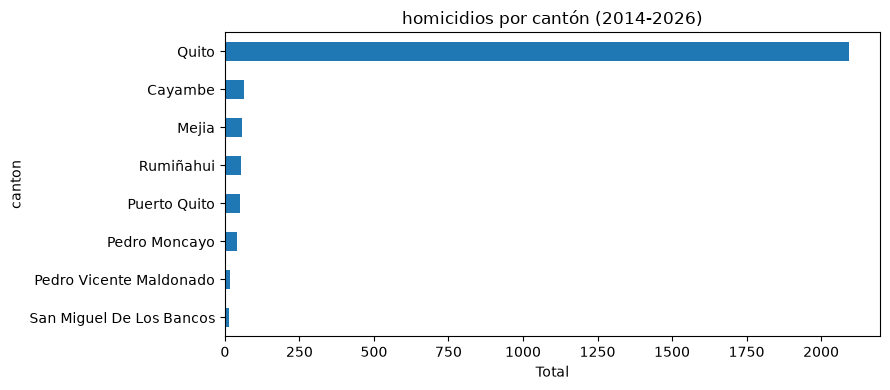

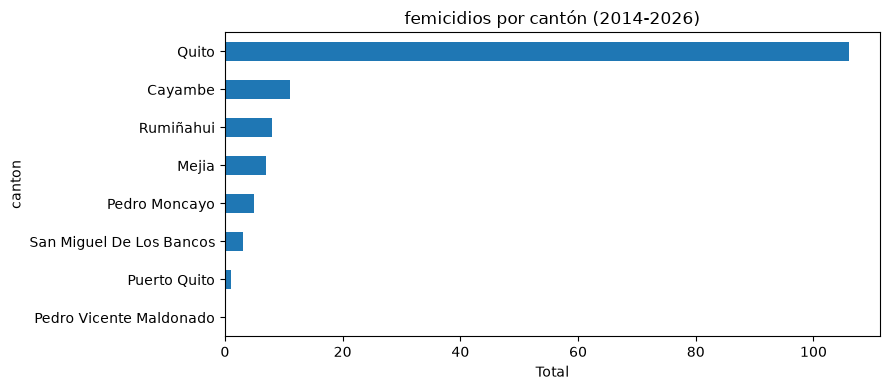

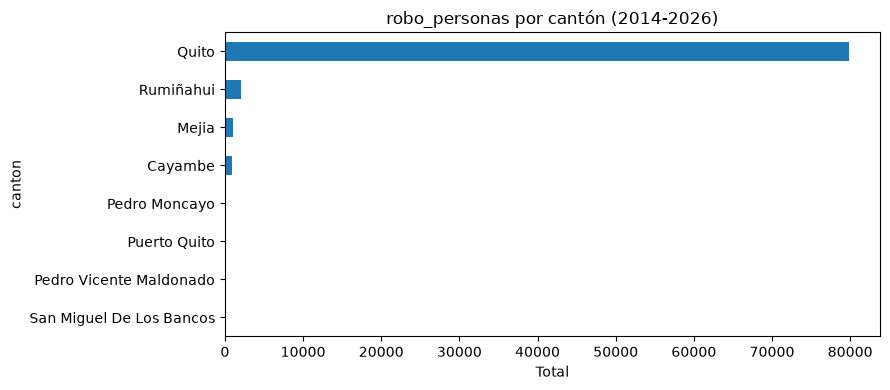

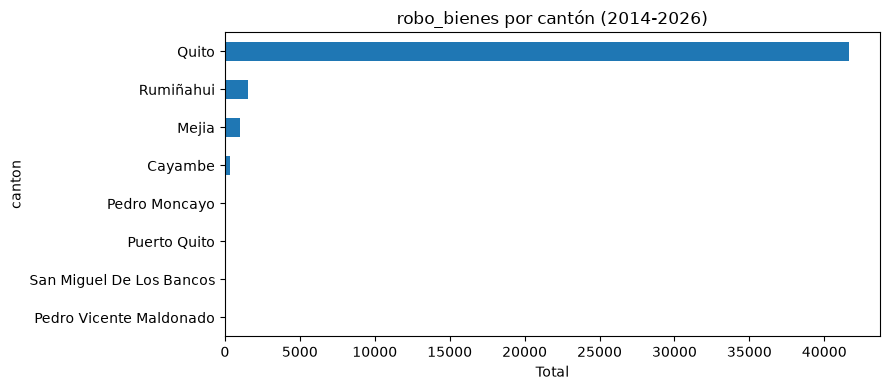

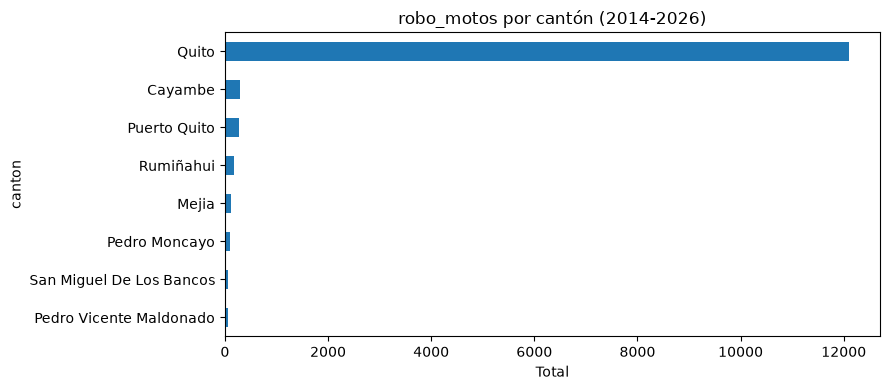

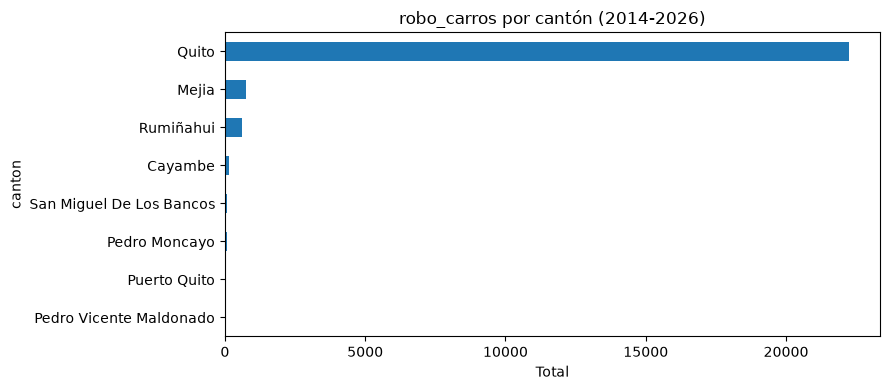

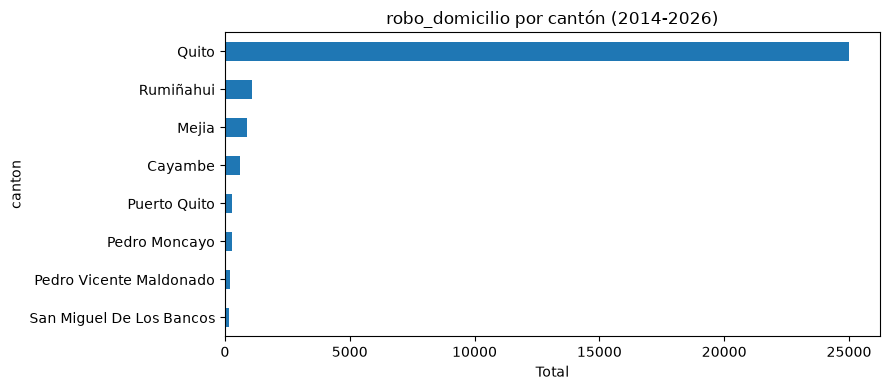

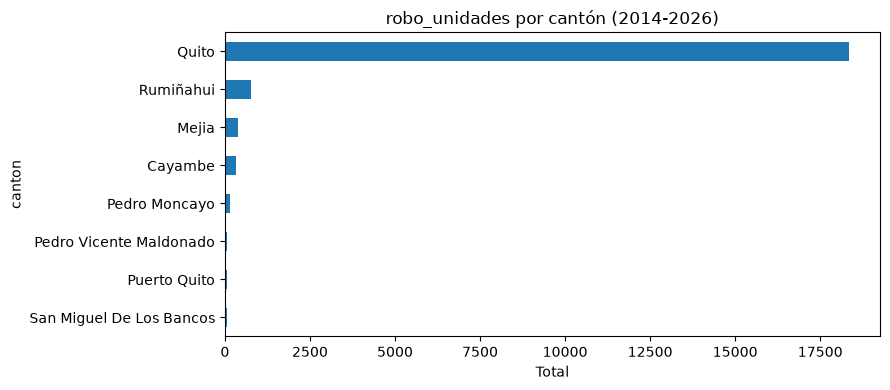

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

tipos = [c for c in cantones.columns
         if c not in ("mes", "codigo_dpa", "canton")]

for col in tipos:
    totales = cantones.groupby("canton")[col].sum().sort_values()
    totales.plot(kind="barh", figsize=(9, 4),
                 title=f"{col} por cantón (2014-2026)")
    plt.xlabel("Total")
    plt.tight_layout(); plt.show()


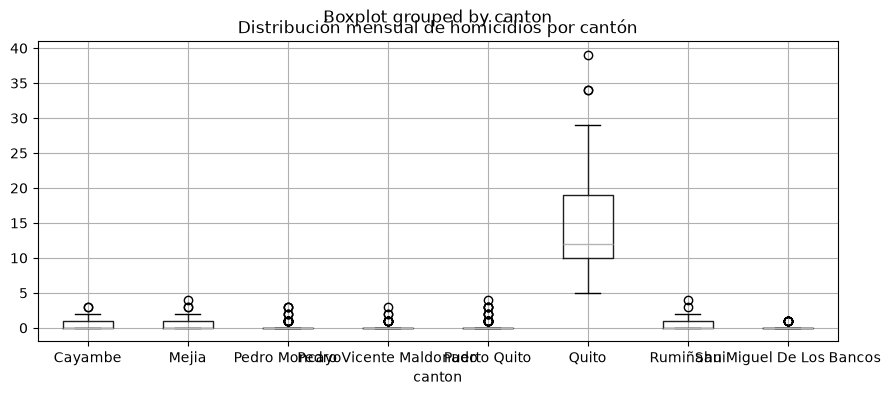

In [10]:
cantones.boxplot(column="homicidios", by="canton", figsize=(10, 4))
plt.title("Distribución mensual de homicidios por cantón"); plt.show()

In [11]:
cantones.describe()

,codigo_dpa,homicidios,femicidios,robo_personas,robo_bienes,robo_motos,robo_carros,robo_domicilio,robo_unidades
count,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000
mean,1704.875000,2.042808,0.120719,72.167808,38.264555,11.243151,20.514555,24.386130,17.274829
std,2.713979,5.250524,0.432187,183.562833,100.289202,28.430811,52.490794,64.676009,42.841058
min,1701.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1702.750000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,1704.500000,0.000000,0.000000,3.000000,1.000000,1.000000,1.000000,3.000000,1.000000
75%,1707.250000,1.000000,0.000000,11.000000,8.000000,2.000000,5.000000,7.000000,4.000000
max,1709.000000,39.000000,4.000000,795.000000,553.000000,133.000000,254.000000,423.000000,234.000000


##Limpiando las columnas

cantones.columns.tolist()

## 1. Convertir Excel a CSV
Una hoja = un CSV:

In [12]:
for hoja in pd.ExcelFile(XLSX).sheet_names:
    df = pd.read_excel(XLSX, sheet_name=hoja)
    destino = CSV_DIR / f"{hoja.strip().replace(' ', '_')}.csv"
    df.to_csv(destino, index=False, encoding='utf-8')
    print(f"{destino.name}: {df.shape[0]} filas x {df.shape[1]} columnas")

Guía.csv: 8 filas x 2 columnas
Provincia.csv: 146 filas x 10 columnas
Cantones.csv: 1168 filas x 12 columnas
Glosario.csv: 12 filas x 2 columnas


## 2. Explorar los datos

In [13]:
provincia = pd.read_csv(CSV_DIR / 'Provincia.csv', parse_dates=['Mes'])
cantones = pd.read_csv(CSV_DIR / 'Cantones.csv', parse_dates=['Mes'])
print('Cobertura temporal:', provincia['Mes'].min().date(), '->', provincia['Mes'].max().date())
print('Cantones de Pichincha:', cantones['Cantón'].unique().tolist())
provincia.head()

Cobertura temporal: 2014-01-01 -> 2026-02-01
Cantones de Pichincha: ['Quito', 'Cayambe', 'Mejia', 'Pedro Moncayo', 'Rumiñahui', 'San Miguel De Los Bancos', 'Pedro Vicente Maldonado', 'Puerto Quito']


,Mes,Provincia,Homicidios intencionales,Femicidios,Denuncias: robo a personas,"Denuncias: robo de bienes, accesorios y autopartes de vehículos",Denuncias: robo de motos,Denuncias: robo de carros,Denuncias: robo a domicilio,Denuncias: robo a unidades económicas
0,2014-01-01,Pichincha,10,0,776,506,71,194,358,224
1,2014-02-01,Pichincha,15,1,637,438,48,140,293,198
2,2014-03-01,Pichincha,14,0,677,521,40,166,336,192
3,2014-04-01,Pichincha,18,0,599,500,57,170,303,184
4,2014-05-01,Pichincha,23,0,719,592,55,196,305,177


In [14]:
cantones.groupby('Cantón')['Homicidios intencionales'].sum().sort_values(ascending=False)

Cantón
Quito                       2093
Cayambe                       63
Mejia                         57
Rumiñahui                     53
Puerto Quito                  49
Pedro Moncayo                 39
Pedro Vicente Maldonado       18
San Miguel De Los Bancos      14
Name: Homicidios intencionales, dtype: int64

## 3. Vista rápida de la tendencia

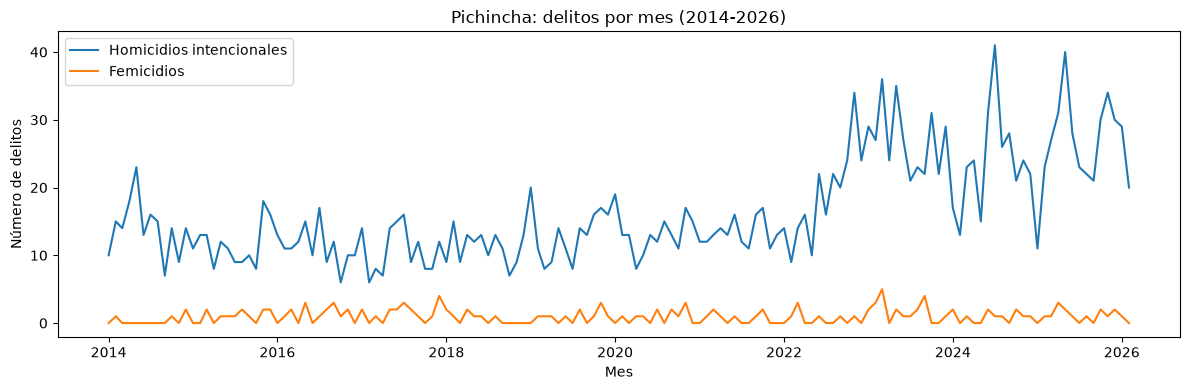

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(provincia['Mes'], provincia['Homicidios intencionales'], label='Homicidios intencionales')
ax.plot(provincia['Mes'], provincia['Femicidios'], label='Femicidios')
ax.set_title('Pichincha: delitos por mes (2014-2026)')
ax.set_xlabel('Mes'); ax.set_ylabel('Número de delitos'); ax.legend()
plt.tight_layout(); plt.show()

## 4. ¿Qué tipos de robo acumulan más denuncias?
Comparamos los totales provinciales de enero de 2014 a febrero de 2026. Cada barra representa una modalidad de robo.

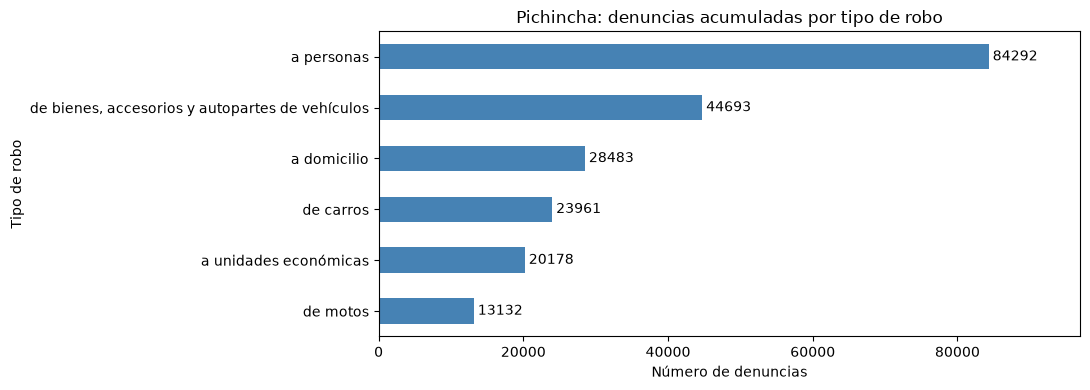

In [16]:
robos = provincia.filter(like='Denuncias: robo')
totales = robos.sum().sort_values()
totales.index = totales.index.str.replace('Denuncias: robo ', '', regex=False)
ax = totales.plot(kind='barh', figsize=(11, 4), color='steelblue')
ax.set_title('Pichincha: denuncias acumuladas por tipo de robo')
ax.set_xlabel('Número de denuncias'); ax.set_ylabel('Tipo de robo')
ax.bar_label(ax.containers[0], padding=3); ax.margins(x=0.15)
plt.tight_layout(); plt.show()

## 5. ¿Cómo cambian los robos de carros y motos?
Comparamos meses, no totales anuales: de 2026 solo hay datos de enero y febrero.

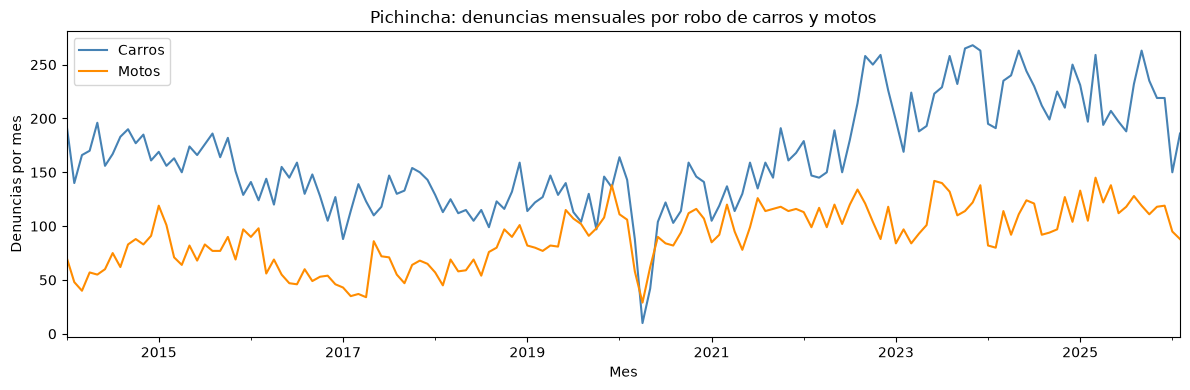

In [17]:
vehiculos = provincia.set_index('Mes')[['Denuncias: robo de carros', 'Denuncias: robo de motos']].sort_index()
ax = vehiculos.plot(figsize=(12, 4), color=['steelblue', 'darkorange'])
ax.set_title('Pichincha: denuncias mensuales por robo de carros y motos')
ax.set_xlabel('Mes'); ax.set_ylabel('Denuncias por mes'); ax.legend(['Carros', 'Motos'])
plt.tight_layout(); plt.show()

## 6. ¿Qué parte de los robos a personas se registra en Quito?
Para cada año completo comparamos Quito con los otros siete cantones juntos. El porcentaje muestra dónde se registraron las denuncias; no mide el riesgo por habitante.

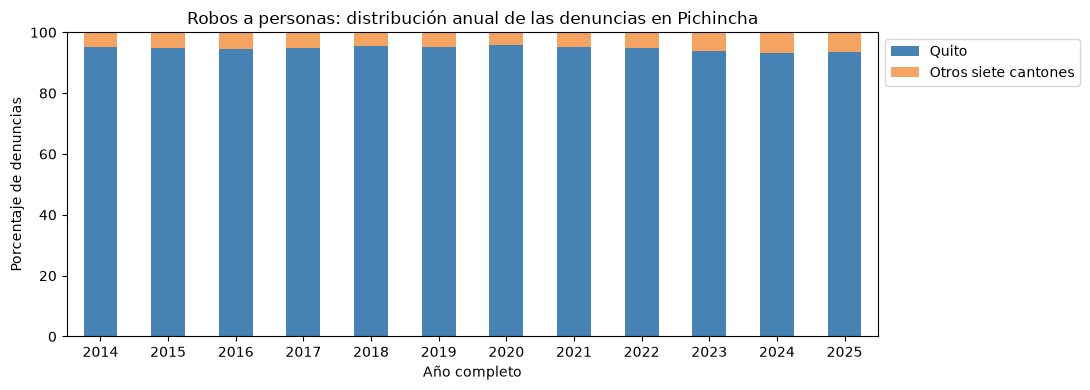

In [18]:
personas = cantones[['Mes', 'Cantón', 'Denuncias: robo a personas']].copy()
personas['Año'] = personas['Mes'].dt.year
personas['Zona'] = personas['Cantón'].map(lambda canton: 'Quito' if canton == 'Quito' else 'Otros siete cantones')
meses_por_zona = personas.groupby(['Año', 'Cantón'])['Mes'].nunique().unstack()
anios_completos = meses_por_zona.index[meses_por_zona.eq(12).all(axis=1)]
por_zona = personas.groupby(['Año', 'Zona'])['Denuncias: robo a personas'].sum().unstack().loc[anios_completos]
porcentaje = por_zona.div(por_zona.sum(axis=1), axis=0) * 100
ax = porcentaje[['Quito', 'Otros siete cantones']].plot(kind='bar', stacked=True, figsize=(11, 4), rot=0,
                                                        color=['steelblue', 'sandybrown'])
ax.set_title('Robos a personas: distribución anual de las denuncias en Pichincha')
ax.set_xlabel('Año completo'); ax.set_ylabel('Porcentaje de denuncias'); ax.set_ylim(0, 100)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

## 7. ¿Qué tipo de delito tiene más registros en Pichincha?
Comparamos los ocho indicadores entre enero de 2014 y febrero de 2026. Los robos se cuentan como denuncias; los homicidios y femicidios, como casos registrados. No sumamos los indicadores ni estimamos delitos no denunciados.

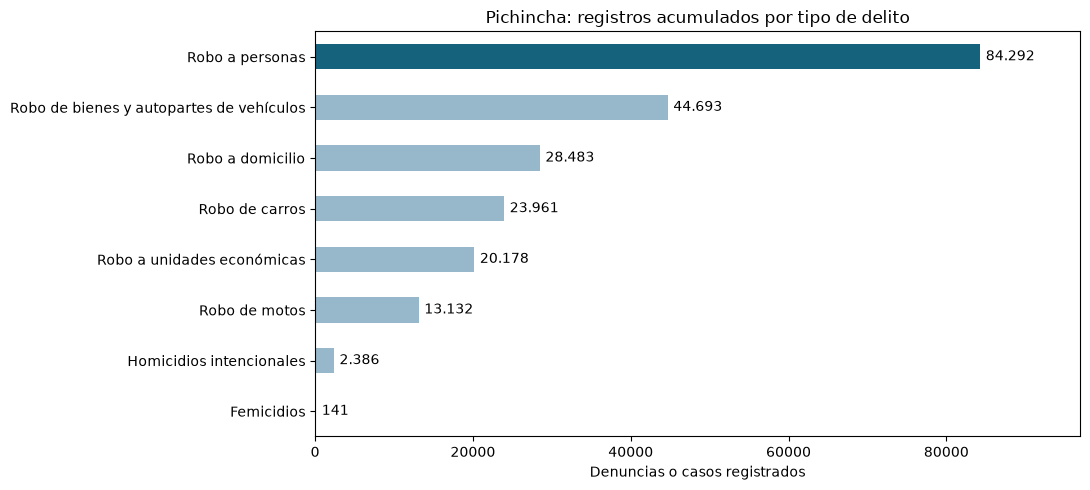

Mayor total: Robo a personas (84292 registros).


In [19]:
etiquetas = {
    'Homicidios intencionales': 'Homicidios intencionales',
    'Femicidios': 'Femicidios',
    'Denuncias: robo a personas': 'Robo a personas',
    'Denuncias: robo de bienes, accesorios y autopartes de vehículos': 'Robo de bienes y autopartes de vehículos',
    'Denuncias: robo de motos': 'Robo de motos',
    'Denuncias: robo de carros': 'Robo de carros',
    'Denuncias: robo a domicilio': 'Robo a domicilio',
    'Denuncias: robo a unidades económicas': 'Robo a unidades económicas',
}
totales = provincia[list(etiquetas)].sum().rename(index=etiquetas).sort_values()
ax = totales.plot.barh(figsize=(11, 5), color=['#97b8ca'] * (len(totales)-1) + ['#14627c'])
ax.bar_label(ax.containers[0], labels=[f'{v:,}'.replace(',', '.') for v in totales], padding=4)
ax.set(title='Pichincha: registros acumulados por tipo de delito', xlabel='Denuncias o casos registrados', ylabel='')
ax.margins(x=0.15); plt.tight_layout(); plt.show()
print(f'Mayor total: {totales.idxmax()} ({totales.max()} registros).')

## 8. ¿Qué cantones tienen más meses con datos atípicos?
Comparamos cada indicador con su propia historia mensual en el mismo cantón. Un valor es atípico si cae por debajo de Q1 − 1,5 × RIC o por encima de Q3 + 1,5 × RIC (RIC = Q3 − Q1). Contamos cada mes una sola vez aunque tenga varios indicadores atípicos. Si casi todos los valores son cero, incluso un solo caso puede destacar: atípico no significa error ni mayor riesgo.

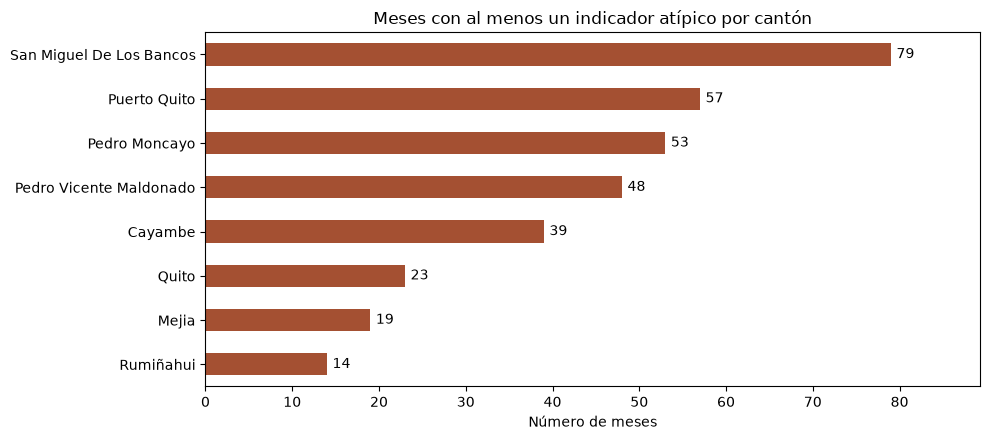

Cantón
San Miguel De Los Bancos    79
Puerto Quito                57
Pedro Moncayo               53
Pedro Vicente Maldonado     48
Cayambe                     39
Quito                       23
Mejia                       19
Rumiñahui                   14


In [20]:
serie = cantones.set_index(['Cantón', 'Mes'])[list(etiquetas)].sort_index()
por_canton = serie.groupby(level='Cantón')
q1 = por_canton.transform('quantile', q=0.25)
q3 = por_canton.transform('quantile', q=0.75)
ric = q3 - q1
atipicos = (serie < q1 - 1.5 * ric) | (serie > q3 + 1.5 * ric)
meses_atipicos = atipicos.any(axis=1).groupby(level='Cantón').sum().sort_values()
ax = meses_atipicos.plot.barh(figsize=(10, 4.5), color='#a45032')
ax.bar_label(ax.containers[0], padding=4, fmt='%d'); ax.margins(x=0.13)
ax.set(title='Meses con al menos un indicador atípico por cantón', xlabel='Número de meses', ylabel='')
plt.tight_layout(); plt.show()
print(meses_atipicos.sort_values(ascending=False).to_string())

## 9. ¿En qué delitos aparecen los datos atípicos de cada cantón?
Cada casilla cuenta los meses atípicos para un solo indicador. Lee por filas para comparar delitos dentro de un cantón. Una fila puede sumar más meses que en el gráfico 8 porque el mismo mes puede destacar en varios delitos.

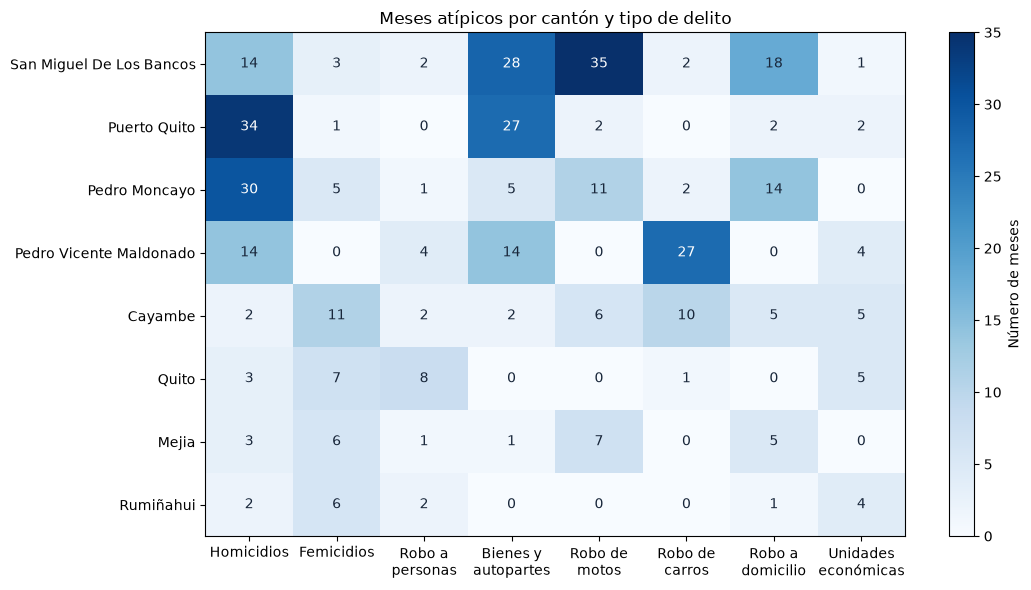

Cantón                                            
San Miguel De Los Bancos  Denuncias: robo de motos    35
Puerto Quito              Homicidios intencionales    34
Pedro Moncayo             Homicidios intencionales    30


In [21]:
detalle = atipicos.groupby(level='Cantón').sum().loc[meses_atipicos.index[::-1]]
fig, ax = plt.subplots(figsize=(11, 6))
imagen = ax.imshow(detalle, cmap='Blues', aspect='auto', vmin=0)
ax.set_xticks(range(len(detalle.columns)), ['Homicidios', 'Femicidios', 'Robo a\npersonas', 'Bienes y\nautopartes', 'Robo de\nmotos', 'Robo de\ncarros', 'Robo a\ndomicilio', 'Unidades\neconómicas'])
ax.set_yticks(range(len(detalle)), detalle.index)
for fila in range(len(detalle)):
    for columna in range(len(detalle.columns)):
        valor = detalle.iloc[fila, columna]
        ax.text(columna, fila, str(valor), ha='center', va='center',
                color='white' if valor > detalle.to_numpy().max() * 0.55 else '#18263a')
ax.set_title('Meses atípicos por cantón y tipo de delito')
fig.colorbar(imagen, ax=ax, label='Número de meses'); fig.tight_layout(); plt.show()
print(detalle.stack().nlargest(3).to_string())

## 10. ¿En qué meses se registran más delitos en cada cantón?
Distinguimos dos preguntas: **qué mes del calendario tiene el promedio más alto** y **en qué mes y año hubo el máximo observado**. El indicador suma las seis categorías de denuncias de robo y los homicidios intencionales. No se suman los femicidios por separado para evitar un posible doble conteo. Es una medida de registros, no de todos los delitos cometidos.

Para el promedio usamos solo años completos (2014–2025): enero y febrero no tienen más peso por los datos parciales de 2026. Para el máximo sí usamos toda la serie hasta febrero de 2026. Se conservan todos los empates.

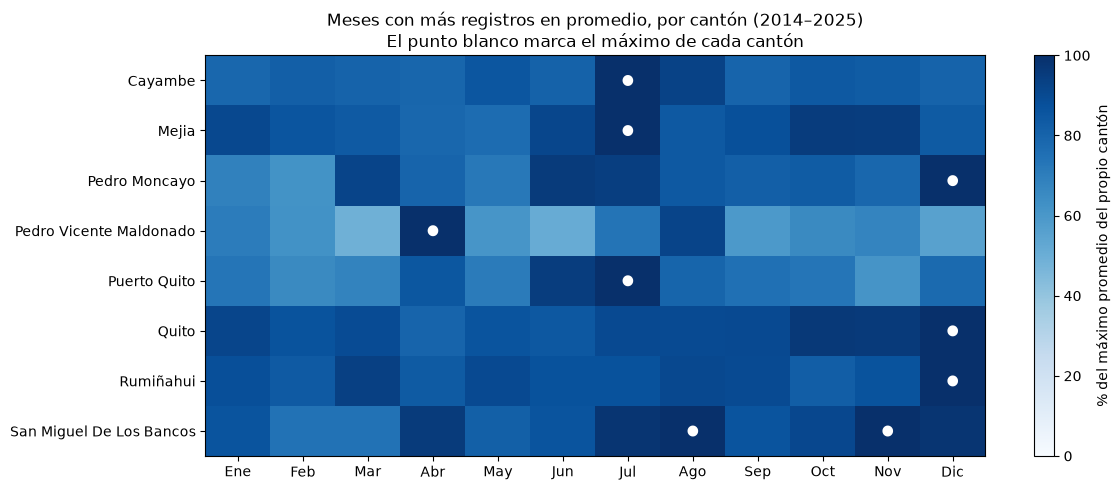

In [2]:
meses_es = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio', 'agosto', 'septiembre', 'octubre', 'noviembre', 'diciembre']
indicadores = ['Homicidios intencionales'] + [c for c in cantones if c.startswith('Denuncias: robo')]
mensual = cantones[['Cantón', 'Mes']].copy()
mensual['Mes'] = pd.to_datetime(mensual['Mes'])
assert len(indicadores) == 7 and not cantones[indicadores].isna().any().any()
assert not mensual.duplicated(['Cantón', 'Mes']).any()
mensual['Registros'] = cantones[indicadores].sum(axis=1)
mensual['Año'] = mensual['Mes'].dt.year
mensual['Número de mes'] = mensual['Mes'].dt.month
cobertura = mensual.groupby(['Año', 'Cantón'])['Número de mes'].nunique().unstack()
completos = cobertura.index[cobertura.eq(12).all(axis=1)]
historia = mensual[mensual['Año'].isin(completos)]
promedios = historia.groupby(['Cantón', 'Número de mes'])['Registros'].mean().unstack()
# Matriz de color relativa al máximo de cada fila; las cifras de la tabla son promedios reales.
relativo = promedios.div(promedios.max(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(relativo, aspect='auto', cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(12), [m[:3].capitalize() for m in meses_es]); ax.set_yticks(range(len(promedios)), promedios.index)
for fila, (_, valores) in enumerate(promedios.iterrows()):
    for mes in valores.index[valores.eq(valores.max())]:
        ax.text(mes-1, fila, '●', ha='center', va='center', color='white')
ax.set_title('Meses con más registros en promedio, por cantón (2014–2025)\nEl punto blanco marca el máximo de cada cantón')
fig.colorbar(im, ax=ax, label='% del máximo promedio del propio cantón')
plt.tight_layout(); plt.show()

In [3]:
resumen = []
for canton, proms in promedios.iterrows():
    serie = mensual[mensual['Cantón'] == canton].sort_values('Mes')
    picos = serie.loc[serie['Registros'].eq(serie['Registros'].max()), 'Mes']
    resumen.append({'Cantón': canton,
                    'Mes de mayor promedio': ', '.join(meses_es[m-1] for m in proms.index[proms.eq(proms.max())]),
                    'Promedio de registros': round(proms.max(), 1),
                    'Mes y año del máximo': ', '.join(f'{meses_es[d.month-1]} {d.year}' for d in picos),
                    'Registros en el máximo': serie['Registros'].max()})
pd.DataFrame(resumen).set_index('Cantón')

,Mes de mayor promedio,Promedio de registros,Mes y año del máximo,Registros en el máximo
Cantón,,,,
Cayambe,julio,21.6,mayo 2015,37
Mejia,julio,33.6,noviembre 2014,51
Pedro Moncayo,diciembre,7.4,"abril 2014, julio 2015, junio 2025",14
Pedro Vicente Maldonado,abril,5.1,febrero 2015,13
Puerto Quito,julio,7.8,diciembre 2015,15
Quito,diciembre,1537.0,octubre 2015,2150
Rumiñahui,diciembre,48.2,abril 2015,95
San Miguel De Los Bancos,"agosto, noviembre",3.6,abril 2016,14
